In [1]:
import numpy as np
import pandas as pd
import os
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from collections import Counter
from preprocess import preprocess
from DataLoader import *


In [2]:
from dotenv import load_dotenv
load_dotenv()
DATASET_PATH = os.getenv("DATASET_PATH")

## data distribution analysis

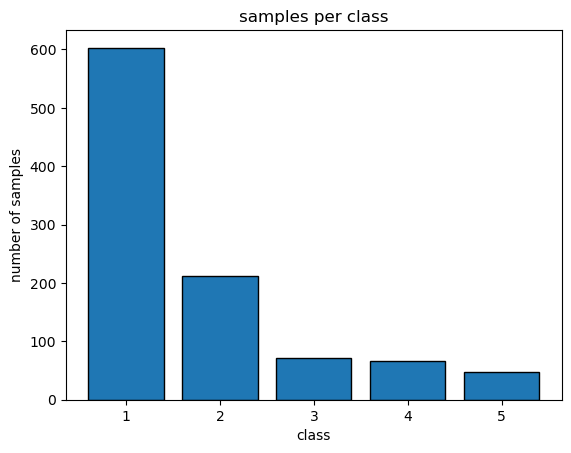

Counter({1: 603, 2: 212, 3: 71, 4: 66, 5: 48})


In [3]:
df = pd.read_csv(os.path.join(DATASET_PATH, "train_labels.csv"))

plt.hist(df["label"],
         bins=[1, 2, 3, 4, 5, 6],
         align='left',
         rwidth=0.8,
         edgecolor='black')
plt.title("samples per class")
plt.xlabel("class")
plt.ylabel("number of samples")
plt.show()

print(Counter(df["label"]))

As we can see the number of patients suffering from malignant cancer are outnumbered by a scale of approximately 1 to 10 by those with benign or marginal cancer types. For dealing with this problem, we have 2 main options :
1. **Over Sampling** : We just oversample the malignant classes and increase the count of samples in this class with data augmentation techniques.
2. **Focal Loss** : Using focal loss or other functions designed for long-tailed datasets to artificially increase the effect of classes with fewer members.

## Image Analysis

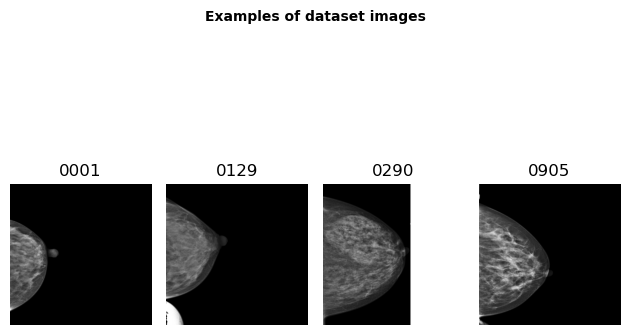

In [4]:
images_path = os.path.join(DATASET_PATH, "images")
fig, axes = plt.subplots(nrows=1, ncols=4)
fig.suptitle("Examples of dataset images", fontsize=10, fontweight='bold')
examples = ["0001","0129","0290","0905"]
for idx, example in enumerate(examples):
    img = Image.open(os.path.join(images_path,f"""train_{example}.png"""))
    axes[idx].imshow(img,cmap="gray")
    axes[idx].set_title(example)
    axes[idx].axis('off')
plt.tight_layout()
plt.show()


There are some main issues with the images in this dataset that need to be delt with. First of all a large portion of each image is completely black, hence no learning value in these parts. We need to find a way to **discard these black (or in the case of 0290 white) parts** and only include the important parts. Other than that some of the images have **letters on the top right part** determining the side the image was taken from. This information is unimportant and can make the model develop some unintended bias. The last problem is that in **some images other than the main part, some other part is in the photo too**. Take 0129 as an example. There is a small part on the bottom left part that is not important.

To deal with these 3 problems using a segmentation method like **watershed** segmentation is a good choice. To be completely honest at first I tried using contours to distinguish between parts in an image. Afterward I just put the largest possible contour as the output. This method did not work as there were some images where the main and secondary part where connected to each other, hence the algorithm considered them as the same object. `Watershed` however distinguishes these 2 parts as different segments, and the bigger part is always the breast.

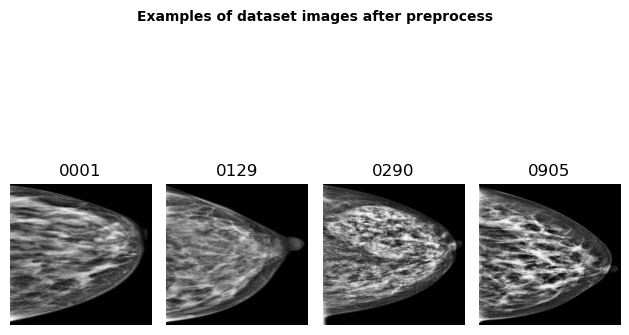

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=4)
fig.suptitle("Examples of dataset images after preprocess", fontsize=10, fontweight='bold')
for idx, example in enumerate(examples):
    axes[idx].imshow(preprocess(example),cmap="gray")
    axes[idx].set_title(example)
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

## Data Loaders

Created Dataframes (800, 2), (200, 2)


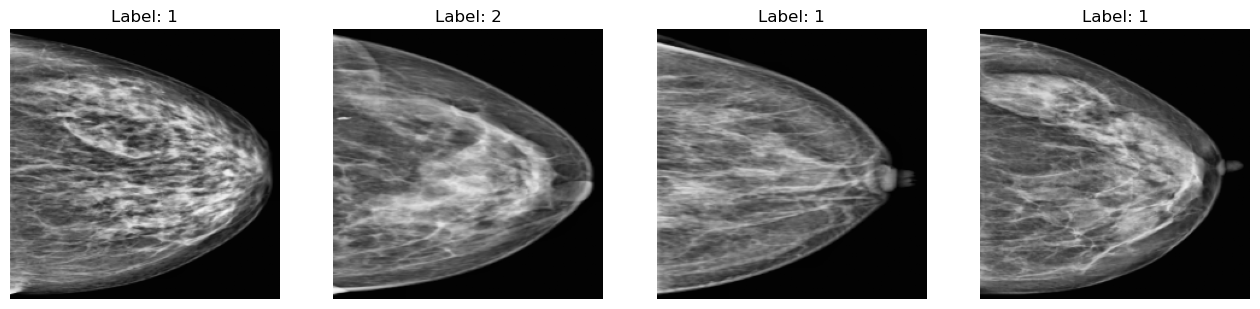

In [6]:
train_loader, test_loader = create_dataloaders(batch_size=8)
show_batch(train_loader)
